# CURRENT | T2D β-cell donor-level exploratory analysis
**GSE81608 (Xin) + GSE86469 (Lawlor)**, analyzed separately. Replaces prior exploratory notebook.

This executed notebook calls the same checked-in script used to generate current results. **No differential-expression tests or pathway analyses are run.** Input expression and metadata must be in the `data/` paths described in README.

**IMPORTANT:** Xin input is RPKM, whose donor summaries are means of log2(1+RPKM), not count pseudobulks. Lawlor expected counts remain fractional and are summed without arbitrary rounding; logCPM is exploratory. Gene mapping and donor independence are not yet fully settled.

In [1]:
from pathlib import Path
import sys, subprocess, pandas as pd, numpy as np, matplotlib
ROOT=Path.cwd()
if not (ROOT/'scripts'/'run_exploratory.py').exists() and (ROOT.parent/'scripts'/'run_exploratory.py').exists():
    ROOT=ROOT.parent
assert (ROOT/'scripts'/'run_exploratory.py').exists(), 'Run this notebook from the repository root or notebooks/ directory'
print('Repository:',ROOT)
print('Python:',sys.version.split()[0], 'pandas:',pd.__version__, 'numpy:',np.__version__,'matplotlib:',matplotlib.__version__)
for f in sorted((ROOT/'data'/'expression').glob('*.csv')):print(f.name,round(f.stat().st_size/1e6,1),'MB')

Repository: /mnt/data/T2D_Task2_Current
Python: 3.13.5 pandas: 2.2.3 numpy: 2.3.5 matplotlib: 3.10.8
GSE81608_expression_RPKM.csv 177.5 MB
GSE86469_expression_RSEM_expected_counts.csv 48.4 MB


## Full reproducible QC and donor aggregation
The analysis script reads all expression entries in batches and creates the donor expression matrices, marker plots, manifest, audit, PCA, and group demographics. It only uses original sample cell types and groups, checks for missing/negative entries, and **does not discard any donors**. The full runnable code is `scripts/run_exploratory.py`.

In [2]:
import subprocess
proc=subprocess.run([sys.executable,str(ROOT/'scripts'/'run_exploratory.py')],cwd=ROOT,stdout=subprocess.PIPE,stderr=subprocess.PIPE,text=True)
print(proc.stdout[-10000:])
if proc.stderr:print('Messages:',proc.stderr[-1600:])
assert proc.returncode==0, f'Exploration script failed with exit code {proc.returncode}'
print('CURRENT WORKFLOW EXECUTED SUCCESSFULLY')

Processing GSE81608
GSE81608: 39,851 genes, 1600 cells, 18 donors, 503 beta cells; 4 markers; fractional positive=9161592/9162358
Processing GSE86469
GSE86469: 26,616 genes, 638 cells, 8 donors, 264 beta cells; 4 markers; fractional positive=3188219/5307880

CURRENT SUMMARY (donor-level, not cell-weighted):
 dataset disease_group  donors  total_cells  beta_cells  age_mean  age_sd  age_min  age_max  sex_F  sex_M  BMI_n  BMI_mean  BMI_sd
GSE81608            ND      12          651         207     39.33   16.43       23       68      5      7      0       NaN     NaN
GSE81608           T2D       6          949         296     47.17    8.26       37       57      3      3      0       NaN     NaN
GSE86469            ND       5          380         168     38.00   15.41       22       56      2      3      5     31.91   13.60
GSE86469           T2D       3          258          96     49.33    6.66       42       55      2      1      3     36.20    6.61
All outputs saved to /mnt/data/T2D_T

## Match and QC tables
These output tables come from this execution, not from archived Task 1 files. β-cell donor units are biological replicates; individual cells are not used as independent donors.

In [3]:
from IPython.display import display
for relative in ['results/qc/matching_audit_CURRENT.csv','results/qc/expression_qc_CURRENT.csv','results/qc/donor_group_demographics_CURRENT.csv']:
 print('\n'+relative)
 display(pd.read_csv(ROOT/relative))


results/qc/matching_audit_CURRENT.csv


,dataset,expression_columns,metadata_rows,matched_cells,unmatched_expression,unmatched_metadata,duplicate_expression_ids,duplicate_metadata_ids,donor_conflicts,header_match_verified
0,GSE81608,1600,1600,1600,0,0,0,0,0,True
1,GSE86469,638,638,638,0,0,0,0,0,True



results/qc/expression_qc_CURRENT.csv


,dataset,genes,cells,duplicate_gene_ids,missing_or_nonfinite_values,negative_values,zero_values,zero_fraction,fractional_positive_entries,positive_entries,fractional_positive_fraction,markers_verified_in_matrix,marker_rows_found,beta_cells,donors,units
0,GSE81608,39851,1600,0,0,0,54599242,0.856303,9161592,9162358,0.999916,"GCG,INS,PPY,SST",4,503,18,RPKM
1,GSE86469,26616,638,0,0,0,11673128,0.687423,3188219,5307880,0.600658,"GCG,INS,PPY,SST",4,264,8,RSEM expected counts



results/qc/donor_group_demographics_CURRENT.csv


,dataset,disease_group,donors,total_cells,beta_cells,age_mean,age_sd,age_min,age_max,sex_F,sex_M,BMI_n,BMI_mean,BMI_sd
0,GSE81608,ND,12,651,207,39.33,16.43,23,68,5,7,0,NaN,NaN
1,GSE81608,T2D,6,949,296,47.17,8.26,37,57,3,3,0,NaN,NaN
2,GSE86469,ND,5,380,168,38.00,15.41,22,56,2,3,5,31.91,13.60
3,GSE86469,T2D,3,258,96,49.33,6.66,42,55,2,1,3,36.20,6.61


## Donor-level exploratory plots
PCA is unsupervised and descriptive. An unusual point is a flag for investigation, **not a justification for exclusion or a disease association**.

GSE81608 donor-level PCA


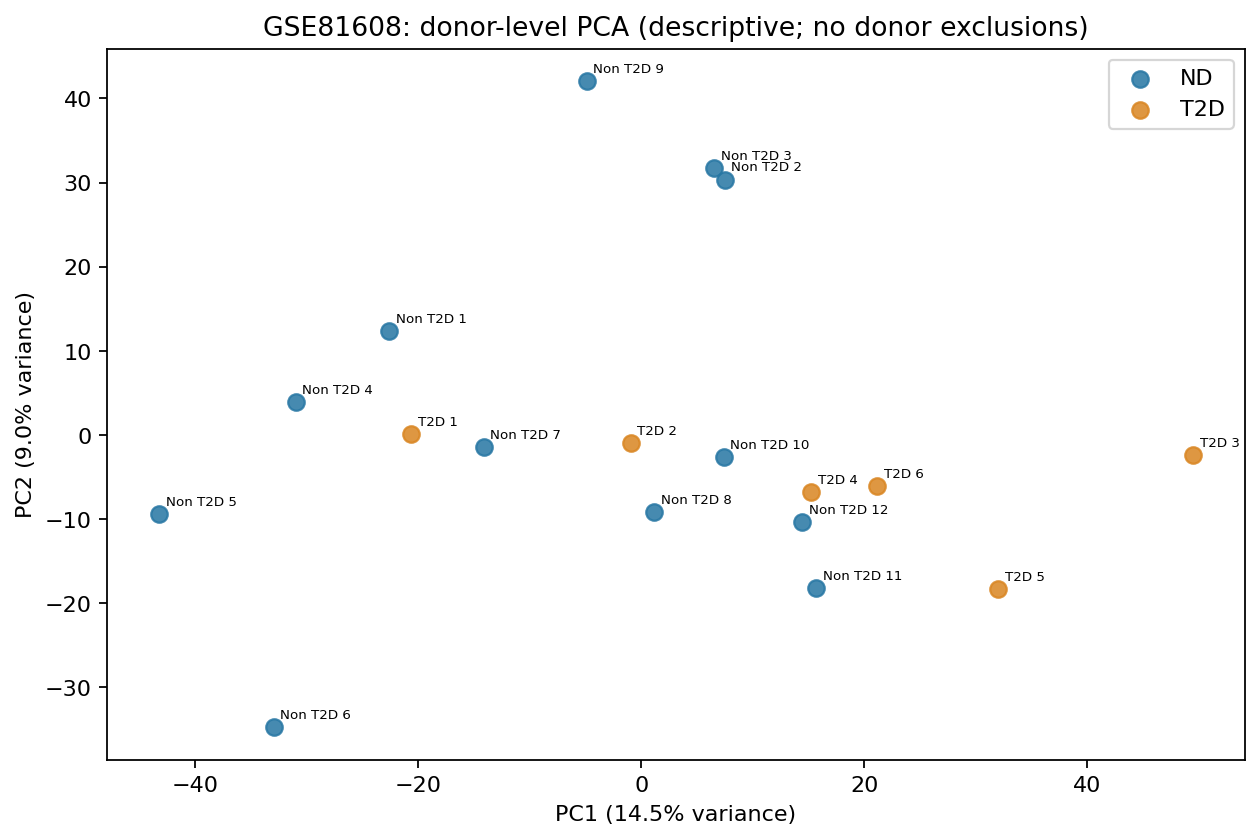

GSE81608 original-annotation marker check


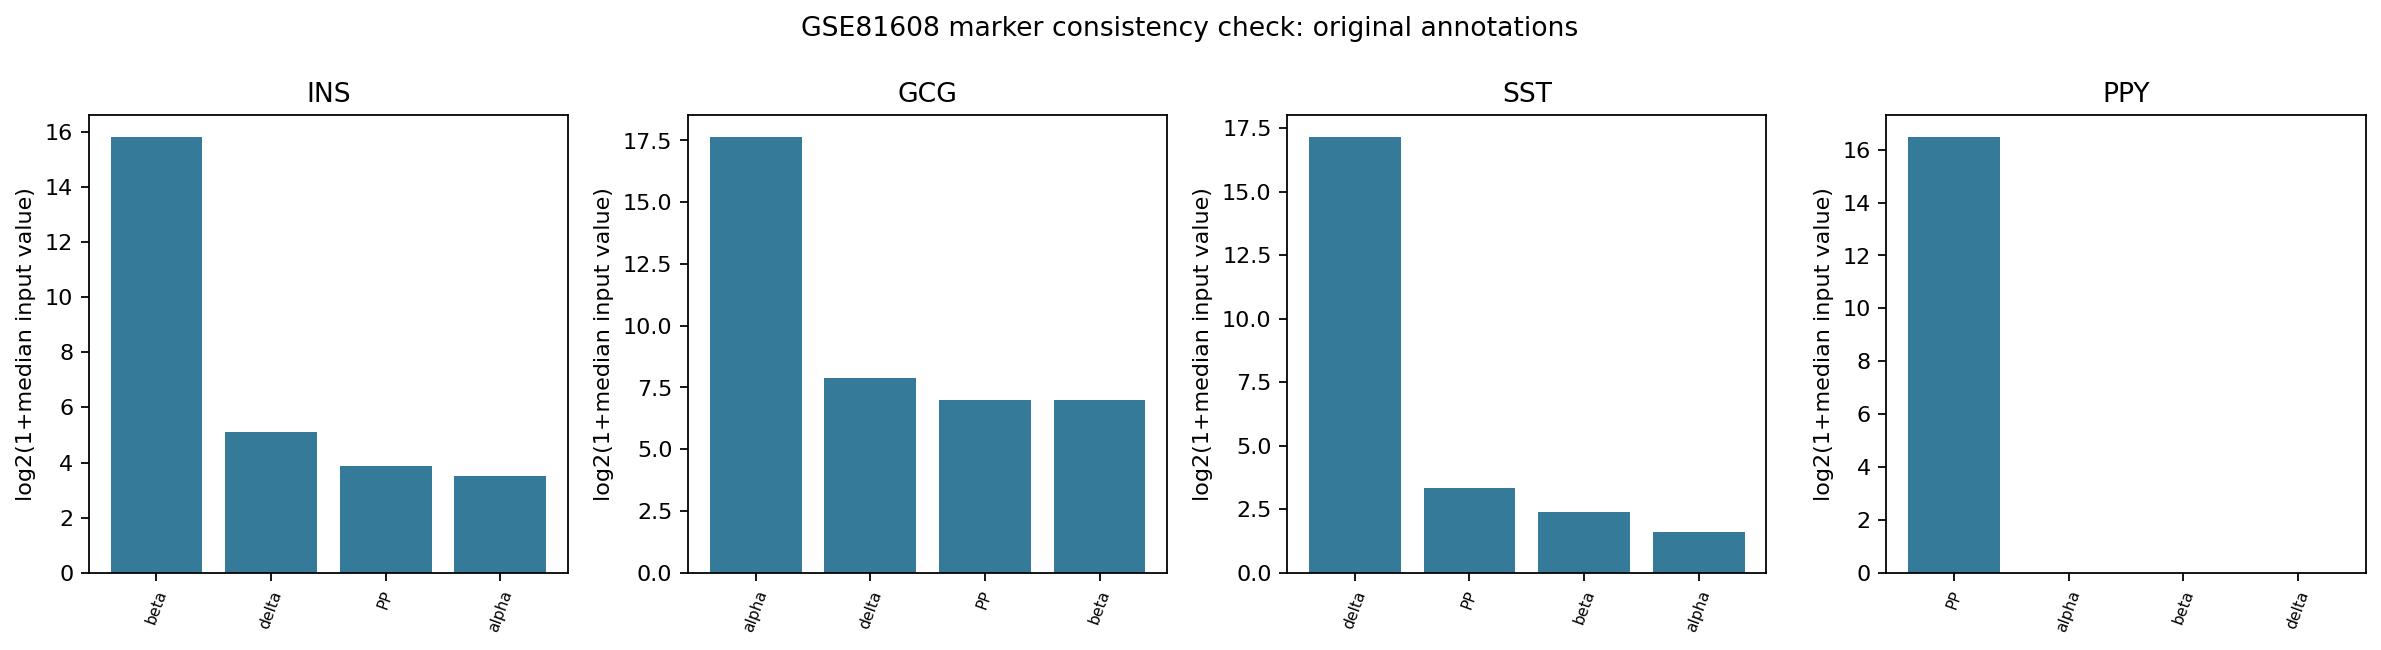

GSE86469 donor-level PCA


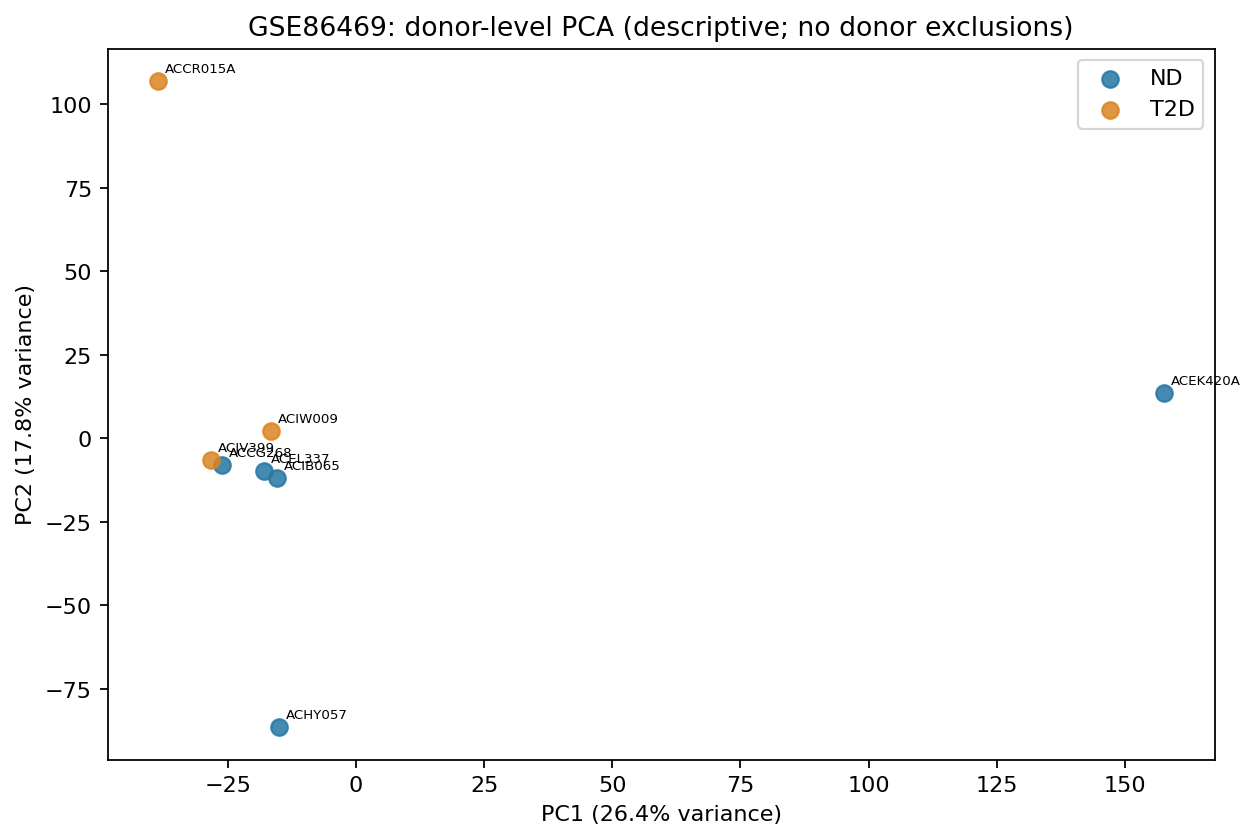

GSE86469 original-annotation marker check


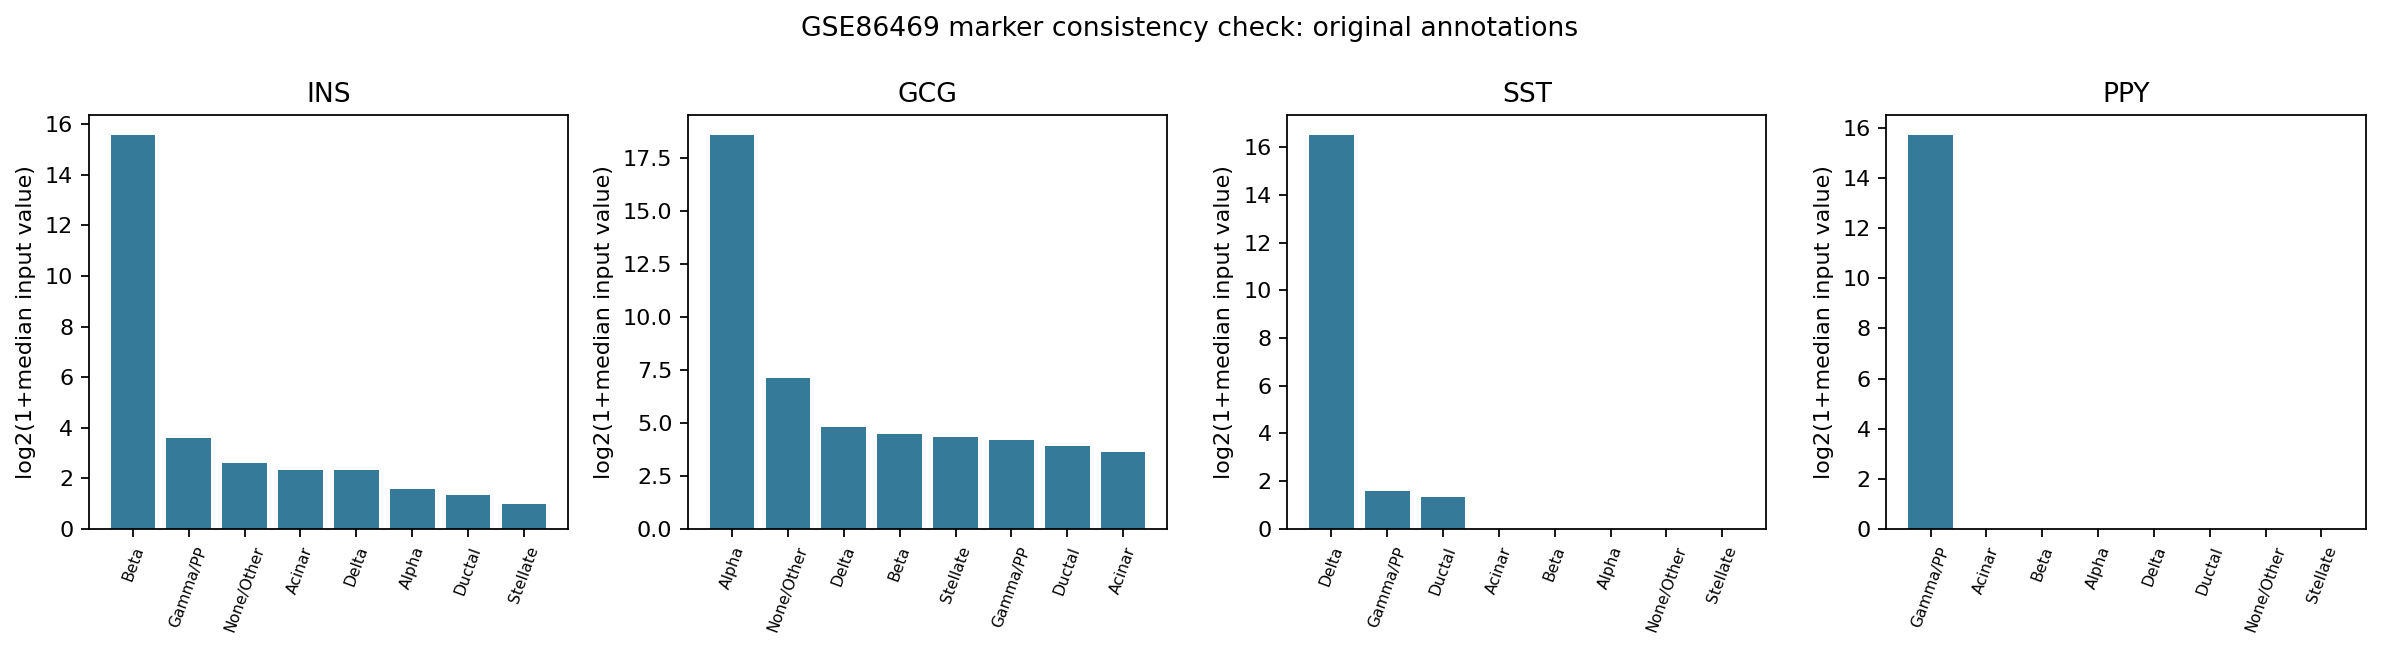

In [4]:
from IPython.display import Image, display
for ds in ['GSE81608','GSE86469']:
 print(ds+' donor-level PCA')
 display(Image(filename=str(ROOT/'results'/'figures'/(ds+'_donor_PCA.png')),width=700))
 print(ds+' original-annotation marker check')
 display(Image(filename=str(ROOT/'results'/'figures'/(ds+'_marker_annotation_check.png')),width=800))

## Outstanding gates
1. Obtain the full NCBI GeneID -> Ensembl crosswalk, report unmapped/ambiguous IDs, compare annotation build. Only four markers are verified in the present offline mapping.
2. Investigate published Xin 1,492 vs deposited 1,600 cells; do not automatically remove 108.
3. Confirm cross-study donor independence from study provenance, not merely labels.
4. Verify original RSEM expected count quantification/normalization before selecting Lawlor DE method.
5. Supervisor approval of `protocol/Two_Page_Statistical_Protocol_FOR_REVIEW.pdf` **before any differential-expression testing**.